# CFO: activar fondeo antes de que llegue tarde

## Resumen
Con demora2períodos, el umbralreactivo2 tiene brecha de caja en50% de masa de los escenarios; el umbralseleccionado6reduce esa masa a0, pagando costo0,74 en vez de0,132. Son escenarios sintéticos, no probabilidad real calibrada ni garantía de supervivencia.

## Modelo e información disponible
Una línea comprometida permite un giro único8, con comisión de solicitud0,5 einterés2%por período sobre principal desembolsado. El principal entra encaja ypasivo simultáneamente: no es ingreso niganancia. Sin amortización dentro del horizonte, caja−deuda= caja inicial+flujosoperativos−costos.

Orden por período: llega fondeo pendiente; se observa caja yse decide solicitud; se paga comisión (yfondea inmediatamente si lead0); se monitorea piso; se liquida flujo neto einterés al cierre yse monitorea de nuevo. La solicitud usa caja observada, contrato yhorizonte, **no el flujo futuro del período**. Se permite solicitar solo si el giro llega dentro del horizonte.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'facility': {'initial_cash': 8,
  'amount': 8,
  'request_fee': 0.5,
  'interest_per_period': 0.02,
  'lead': 2,
  'floor': 0},
 'thresholds': [None, 0, 2, 4, 6, 8],
 'max_breach': 0.1,
 'weights': [0.5, 0.3, 0.2],
 'names': ['normal', 'sustained_burn', 'frontloaded_burn'],
 'flows': [[-1, -1, 1, 1, 1], [-2, -2, -2, -2, -2], [-4, -2, -1, -1, -1]],
 'hypothesis': 'menu threshold can reduce scenario breach probability vs reactive threshold2 at extra financing cost; max scenario breach0.1',
 'units': 'synthetic monetary units per arbitrary period; committed facility certain, one draw, no principal repayment inside horizon'}

## Comparación de políticas
El menú incluye no solicitar. Se minimiza costo esperado sujeto a brecha≤10% de masa de escenarios. La política threshold6 queda fijada exante yse aplica igual atodos caminos.

,threshold,breach_probability,expected_cost
0,NaN,0.5,0.000
1,0.0,0.5,0.000
2,2.0,0.5,0.132
3,4.0,0.3,0.362
4,6.0,0.0,0.740
5,8.0,0.0,0.980


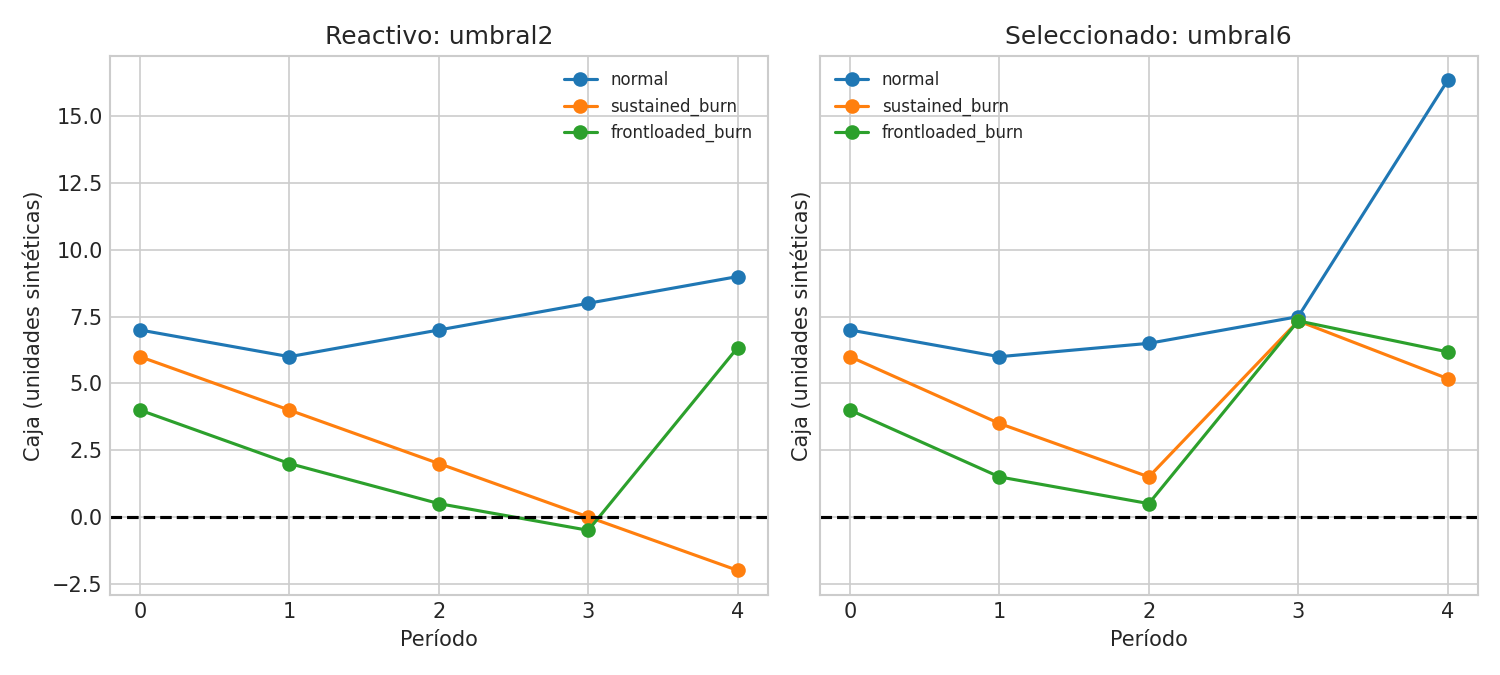

,policy,scenario,period,cash,debt,request_period,funding_period,first_breach,costs_total,reconciliation_error
0,reactive2,normal,0,7.00,0.0,NaN,NaN,NaN,0.00,0.0
1,reactive2,normal,1,6.00,0.0,NaN,NaN,NaN,0.00,0.0
2,reactive2,normal,2,7.00,0.0,NaN,NaN,NaN,0.00,0.0
3,reactive2,normal,3,8.00,0.0,NaN,NaN,NaN,0.00,0.0
4,reactive2,normal,4,9.00,0.0,NaN,NaN,NaN,0.00,0.0
5,reactive2,sustained_burn,0,6.00,0.0,NaN,NaN,4.0,0.00,0.0
6,reactive2,sustained_burn,1,4.00,0.0,NaN,NaN,4.0,0.00,0.0
7,reactive2,sustained_burn,2,2.00,0.0,NaN,NaN,4.0,0.00,0.0
8,reactive2,sustained_burn,3,0.00,0.0,NaN,NaN,4.0,0.00,0.0
9,reactive2,sustained_burn,4,-2.00,0.0,NaN,NaN,4.0,0.00,0.0


In [2]:
display(pd.read_csv('results/thresholds.csv').round(4))
display(Image(filename='results/funding.png'))
display(pd.read_csv('results/trajectories.csv').round(4))

## Fallos, sensibilidad y reconciliación
Fuera del diseño, un burn−4por período produce incumplimiento incluso con el umbral elegido. Una demora mayor puede volver vacío elmenú factible. No se reemplaza falta de factibilidad con un resultado seguro inventado. El simulador sigue aritméticamente después de brecha solo para diagnóstico, no como continuación empresarial viable.

In [3]:
display(pd.read_csv('results/lead-sensitivity.csv'))
display(summary['out_of_design_stress'])
assert summary['selected']['breach_probability']<=cfg['max_breach']
assert all(r['reconciliation_error']<1e-10 for r in summary['selected']['outcomes'])

,lead,threshold,breach_probability,expected_cost,feasible
0,0,0.0,0.0,0.330,True
1,1,4.0,0.0,0.442,True
2,2,6.0,0.0,0.740,True
3,3,8.0,0.0,0.820,True
4,4,NaN,NaN,NaN,False


{'threshold': 6,
 'breach_probability': 1,
 'expected_cost': 0.8200000000000001,
 'outcomes': [{'request_period': 1,
   'funding_period': 3,
   'first_breach': 1,
   'cash': [4.0, -0.5, -4.5, -0.6600000000000001, -4.82],
   'debt': [0.0, 0.0, 0.0, 8.0, 8.0],
   'observed_cash': [8, 4.0, -0.5, 3.5, -0.6600000000000001],
   'costs': 0.8200000000000001,
   'reconciliation_error': 0.0}]}

## Decisión y límites
Continuar con solicitud al observar caja≤6solo bajo contrato/escenariosdefendibles; ajustar buffer omonto si aumenta la demora; rediseñar liquidez si ningún umbral es factible. No incluye revocación de líneas, covenants, vencimiento, costo de compromiso, amortización, financiación estatal nivalidación regulatoria. ComponenteS2 sintético; no una recomendación financiera real.